# Pipeline Step 4 — Synthetic Generation and Quality Gate
**GWU Praxis, Chapter 3 (Section 3.6)**

Samples the latent space of each trained VAE to generate synthetic out-of-distribution hard negatives from the **known classes only**, then passes every record through the three-stage quality gate.

- **Budget (Section 3.6.1):** synthetic records make up 20% of the Experiment B training set, i.e. n_synth = n_real × 0.20 / 0.80 (Eq. 3.6). Split 50% tail sampling, 30% boundary interpolation, 20% noise injection.
- **Gate (Section 3.6.2):** (1) projection of every decoded record onto valid feature values (one-hot groups, whole-number features), with a finite / [0, 1] guard; (2) reconstruction BCE above training mean + 2 SD is discarded; (3) SHAP pre-validation with a small classifier (input → 64 → n_classes): a record is discarded if the Spearman ρ between its SHAP values and the real class ranking, over that class's top-10 features, is below 0.5.
- **Acceptance (Section 3.6.3):** share of generated records passing all three checks; below 85% is flagged for the retraining rule.

Every accepted record is labelled **`Synthetic-OOD`**; the class it was sampled from is kept in `source_class` for the H3 analysis. 10% of accepted records are reserved for H3 and never used in training.

**The held-out class is never read in this step.**

**Requires:** Steps 1–3. **Produces** (in `outputs_praxis_heldout/SynthGen/`): `*_synthetic_ood.csv`, `quality_gate_report.csv`, distribution plots.

## 0 · Imports and settings

In [1]:
# ────────────────────────────────────────────────────────────────────────────
# IMPORTS, SEED AND SESSION SETUP
# ────────────────────────────────────────────────────────────────────────────
import os, pickle, random, warnings, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from scipy.stats import rankdata

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
keras.utils.set_random_seed(RANDOM_SEED)

# Set this to your project folder in Google Drive (it must end with "/").
BASE = os.environ.get("PRAXIS_BASE", "/content/drive/MyDrive/<YOUR_PROJECT_FOLDER>/")
RUN_DIR = "outputs_praxis_heldout"   # results folder
if "PRAXIS_BASE" not in os.environ:
    from google.colab import drive
    drive.mount("/content/drive")
PIPE = Path(BASE) / RUN_DIR / "pipeline"
VAED = Path(BASE) / RUN_DIR / "VAETrain"
OUT = Path(BASE) / RUN_DIR / "SynthGen"
OUT.mkdir(parents=True, exist_ok=True)
DATASETS = ["CIC-IDS2017", "UNSW-NB15", "NSL-KDD"]
OOD_LABEL = "Synthetic-OOD"

Mounted at /content/drive


In [2]:
# ────────────────────────────────────────────────────────────────────────────
# GENERATION AND GATE SETTINGS (Section 3.6)
#
# MAX_SYNTH caps the budget per dataset if memory is tight (None = no cap);
# if a cap is used, Chapter 3 must state it.
# MAX_ROUNDS: extra generation rounds are run until the budget of accepted
# records is met; the acceptance rate is always reported from round 1.
# ────────────────────────────────────────────────────────────────────────────
SYNTH_SHARE = 0.20                          # of the Experiment B training set
STRATEGY_SHARE = {"tail": 0.50, "interpolation": 0.30, "noise": 0.20}
MAX_SYNTH = {"CIC-IDS2017": None, "UNSW-NB15": None, "NSL-KDD": None}
H3_RESERVE = 0.10                           # accepted records kept out of training for H3
MAX_ROUNDS = 5

TAIL_MIN, TAIL_MAX = 1.5, 2.5               # tail radius in class SDs (Eq. 3.3)
LAMBDA_MIN, LAMBDA_MAX = 0.2, 0.8           # interpolation weight (Eq. 3.4)
INTERP_NEIGHBOURS = 3                       # interpolate only towards the 3 nearest class means
NOISE_SCALE = 0.4                           # noise SD as a multiple of class SD (Eq. 3.5)

RECON_SIGMA_THRESH = 2.0                    # Section 3.6.2 (Eq. 3.7)
SHAP_TOPK, SHAP_RHO_THRESH = 10, 0.5        # Section 3.6.2
SHAP_REF_PER_CLASS = 500                    # real records per class for the reference ranking
SHAP_BACKGROUND = 64                        # background records for expected-gradients SHAP
SHAP_DRAWS = 16                             # background/path draws per explained record
SURROGATE_ROWS = 200_000                    # real training rows used to fit the gate classifier
ACCEPTANCE_THRESH = 0.85                    # Section 3.6.3

## 1 · Load data and trained VAEs

In [3]:
# ────────────────────────────────────────────────────────────────────────────
# LOAD TRAINING DATA
# Only the known-class training split is loaded; the held-out set is not.
# ────────────────────────────────────────────────────────────────────────────
splits = {}
for name in DATASETS:
    meta = pickle.load(open(PIPE / f"{name}_preprocess.pkl", "rb"))
    fc, lab = meta["feat_cols"], meta["label_col"]
    train = pd.read_csv(PIPE / f"{name}_train.csv")
    assert not train[lab].isin(meta["holdout"]).any()
    splits[name] = dict(X=train[fc].to_numpy(np.float32), y=train[lab].astype(str).to_numpy(),
                        feat_cols=fc, label_col=lab, holdout=meta["holdout"])
    print(f"{name}: {len(train):,} training records, {len(fc)} features")

CIC-IDS2017: 1,765,639 training records, 45 features
UNSW-NB15: 112,901 training records, 49 features
NSL-KDD: 103,464 training records, 92 features


In [4]:
# ────────────────────────────────────────────────────────────────────────────
# REBUILD THE VAE AND LOAD STEP 3 WEIGHTS
# The architecture must match Step 3 exactly for the weights to load. Only the
# encoder and decoder are used here.
# ────────────────────────────────────────────────────────────────────────────
def build_encoder(input_dim, latent_dim):
    inp = keras.Input(shape=(input_dim,), name="encoder_input")
    x = inp
    for i, units in enumerate([256, 128, 64], 1):
        x = layers.Dense(units, name=f"enc_d{i}")(x)
        x = layers.BatchNormalization(name=f"enc_bn{i}")(x)
        x = layers.ReLU(name=f"enc_r{i}")(x)
    return keras.Model(inp, [layers.Dense(latent_dim, name="z_mean")(x),
                             layers.Dense(latent_dim, name="z_log_var")(x)], name="encoder")

def build_decoder(latent_dim, output_dim):
    inp = keras.Input(shape=(latent_dim,), name="decoder_input")
    x = inp
    for i, units in enumerate([64, 128, 256], 1):
        x = layers.Dense(units, name=f"dec_d{i}")(x)
        x = layers.BatchNormalization(name=f"dec_bn{i}")(x)
        x = layers.ReLU(name=f"dec_r{i}")(x)
    return keras.Model(inp, layers.Dense(output_dim, activation="sigmoid", name="dec_output")(x), name="decoder")

class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        return z_mean + tf.exp(0.5 * z_log_var) * tf.random.normal(shape=tf.shape(z_mean))

class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder, self.decoder, self.sampling = encoder, decoder, Sampling()
        self.beta = tf.Variable(0.0, trainable=False, dtype=tf.float32)
        self.total_tracker = keras.metrics.Mean(name="loss")
        self.recon_tracker = keras.metrics.Mean(name="recon_loss")
        self.kl_tracker = keras.metrics.Mean(name="kl_loss")

    def call(self, inputs, training=False):
        z_mean, z_log_var = self.encoder(inputs, training=training)
        return self.decoder(self.sampling([z_mean, z_log_var]), training=training), z_mean, z_log_var

vaes, latent_dim = {}, {}
for name in DATASETS:
    cfg = pickle.load(open(VAED / f"{name}_vae_config.pkl", "rb"))
    assert cfg["feat_cols"] == splits[name]["feat_cols"], f"{name}: feature columns differ from Step 3"
    vae = VAE(build_encoder(cfg["input_dim"], cfg["latent_dim"]), build_decoder(cfg["latent_dim"], cfg["input_dim"]))
    vae(np.zeros((1, cfg["input_dim"]), np.float32))
    vae.load_weights(VAED / f"{name}_vae_final.weights.h5")
    vaes[name], latent_dim[name] = vae, cfg["latent_dim"]
    print(f"{name}: VAE loaded (d_z={cfg['latent_dim']})")

def encode(vae, X):  # posterior means, in batches to limit memory
    return vae.encoder.predict(X, batch_size=8192, verbose=0)[0]

def decode(vae, Z):
    return vae.decoder.predict(Z.astype(np.float32), batch_size=8192, verbose=0)

def bce_per_record(X, R):
    R = np.clip(R, 1e-7, 1 - 1e-7)
    return -np.mean(X * np.log(R) + (1 - X) * np.log(1 - R), axis=1)

CIC-IDS2017: VAE loaded (d_z=8)
UNSW-NB15: VAE loaded (d_z=8)
NSL-KDD: VAE loaded (d_z=8)


In [5]:
# ────────────────────────────────────────────────────────────────────────────
# STAGE 1 — PROJECTION TO THE VALID FEATURE DOMAIN (Section 3.6.2)
#
# The decoder ends in a sigmoid, so every decoded value already lies in [0, 1]:
# a range check alone can never reject a record. Stage 1
# therefore projects each decoded record onto values a real record can take:
#   • one-hot groups (protocol, service, flag, state): the largest member is set
#     to 1 and the others to 0; if no member reaches 0.5 the group is left all
#     zero, which is what a category removed by feature screening looks like;
#   • features that are whole numbers in every training record (counts, flags,
#     ports) are rounded in original units, then rescaled.
# The finite / [0, 1] check is kept as a guard. Stages 2 and 3 then judge the
# projected record, so every accepted record is physically valid.
# ────────────────────────────────────────────────────────────────────────────
projectors = {}
for name in DATASETS:
    meta = pickle.load(open(PIPE / f"{name}_preprocess.pkl", "rb"))
    scaler = pickle.load(open(PIPE / f"{name}_scaler.pkl", "rb"))
    fc = splits[name]["feat_cols"]
    pos = {f: j for j, f in enumerate(fc)}
    groups = []
    if meta.get("onehot") is not None:
        for col, cats in zip(meta["onehot"].feature_names_in_, meta["onehot"].categories_):
            idx = [pos[f"{col}_{c}"] for c in cats if f"{col}_{c}" in pos]
            if idx:
                groups.append(np.array(idx))
    in_group = np.zeros(len(fc), bool)
    for g in groups:
        in_group[g] = True
    rng = np.random.default_rng(RANDOM_SEED)
    X = splits[name]["X"]
    raw = scaler.inverse_transform(X[rng.choice(len(X), size=min(200_000, len(X)), replace=False)])
    is_int = np.all(np.abs(raw - np.round(raw)) < 1e-6, axis=0) & ~in_group
    projectors[name] = dict(scaler=scaler, groups=groups, is_int=is_int)
    print(f"{name}: {len(groups)} one-hot groups ({int(in_group.sum())} columns), "
          f"{int(is_int.sum())} integer-valued features of {len(fc)}")

def project(name, X):
    pj = projectors[name]
    X = X.astype(np.float64).copy()
    for g in pj["groups"]:
        sub = X[:, g]
        keep = sub.max(axis=1) >= 0.5
        new = np.zeros_like(sub)
        new[np.arange(len(sub)), sub.argmax(axis=1)] = keep
        X[:, g] = new
    if pj["is_int"].any():
        raw = pj["scaler"].inverse_transform(X)
        raw[:, pj["is_int"]] = np.round(raw[:, pj["is_int"]])
        X[:, pj["is_int"]] = pj["scaler"].transform(raw)[:, pj["is_int"]]
    return np.clip(X, 0.0, 1.0).astype(np.float32)

CIC-IDS2017: 0 one-hot groups (0 columns), 9 integer-valued features of 45
UNSW-NB15: 3 one-hot groups (16 columns), 11 integer-valued features of 49
NSL-KDD: 3 one-hot groups (65 columns), 12 integer-valued features of 92


## 2 · Per-class latent statistics
Each known class is summarised in latent space by the mean and standard deviation of its records' posterior means.

In [6]:
# ────────────────────────────────────────────────────────────────────────────
# CLASS MEANS AND SDs IN LATENT SPACE
# Also stores each training record's latent code (reused by noise injection).
# ────────────────────────────────────────────────────────────────────────────
latent = {}
for name in DATASETS:
    s = splits[name]
    Z = encode(vaes[name], s["X"])
    stats = {c: dict(mean=Z[s["y"] == c].mean(axis=0), std=Z[s["y"] == c].std(axis=0) + 1e-6,
                     n=int((s["y"] == c).sum())) for c in np.unique(s["y"])}
    latent[name] = dict(Z=Z, stats=stats)
    print(f"{name}: {len(stats)} known classes encoded")

CIC-IDS2017: 14 known classes encoded
UNSW-NB15: 9 known classes encoded
NSL-KDD: 32 known classes encoded


## 3 · Three latent sampling strategies (Section 3.6.1)
- **Tail sampling:** z = μ_c + d ⊙ r ⊙ σ_c, r ~ U(1.5, 2.5), d ~ U{−1, +1} — equal share per class.
- **Boundary interpolation:** z = λ μ_i + (1 − λ) μ_j, λ ~ U(0.2, 0.8), between a class and one of its 3 nearest classes in latent space. The source class is whichever mean has the larger weight.
- **Noise injection:** z = μ(x) + η, η ~ N(0, (0.4 σ_c)²), for randomly chosen training records x.

In [7]:
# ────────────────────────────────────────────────────────────────────────────
# SAMPLING FUNCTIONS (vectorised)
# Each returns latent points Z and the source class of every point.
# ────────────────────────────────────────────────────────────────────────────
def tail_sample(stats, n, rng):
    classes = sorted(stats)
    src = np.array(classes)[np.arange(n) % len(classes)]          # equal share per class
    mu = np.stack([stats[c]["mean"] for c in src]); sd = np.stack([stats[c]["std"] for c in src])
    r = rng.uniform(TAIL_MIN, TAIL_MAX, size=mu.shape)
    d = rng.choice([-1.0, 1.0], size=mu.shape)
    return mu + d * r * sd, src

def interpolation_sample(stats, n, rng):
    classes = sorted(stats)
    M = np.stack([stats[c]["mean"] for c in classes])
    dist = ((M[:, None, :] - M[None, :, :]) ** 2).sum(-1)
    np.fill_diagonal(dist, np.inf)
    k = min(INTERP_NEIGHBOURS, len(classes) - 1)
    nbrs = np.argsort(dist, axis=1)[:, :k]
    i = rng.integers(0, len(classes), n)
    j = nbrs[i, rng.integers(0, k, n)]
    lam = rng.uniform(LAMBDA_MIN, LAMBDA_MAX, size=(n, 1))
    src = np.where(lam[:, 0] >= 0.5, np.array(classes)[i], np.array(classes)[j])
    return lam * M[i] + (1 - lam) * M[j], src

def noise_sample(stats, Z_train, y_train, n, rng):
    idx = rng.integers(0, len(Z_train), n)
    src = y_train[idx]
    sd = np.stack([stats[c]["std"] for c in src])
    return Z_train[idx] + rng.normal(0.0, 1.0, size=sd.shape) * NOISE_SCALE * sd, src

def generate(name, n, rng):
    s, L = splits[name], latent[name]
    counts = {k: int(round(n * v)) for k, v in STRATEGY_SHARE.items()}
    counts["noise"] = n - counts["tail"] - counts["interpolation"]
    parts = [("tail", *tail_sample(L["stats"], counts["tail"], rng)),
             ("interpolation", *interpolation_sample(L["stats"], counts["interpolation"], rng)),
             ("noise", *noise_sample(L["stats"], L["Z"], s["y"], counts["noise"], rng))]
    Z = np.concatenate([p[1] for p in parts]).astype(np.float32)
    src = np.concatenate([p[2] for p in parts])
    strat = np.concatenate([[p[0]] * len(p[1]) for p in parts])
    return project(name, decode(vaes[name], Z)), src, strat


## 4 · Quality gate (Section 3.6.2)
**Stage 3 — SHAP pre-validation.** A small classifier (input → 64 → n_classes, as specified) is trained on real known-class records. SHAP values are computed with *expected gradients*, the method behind `shap.GradientExplainer`, implemented in batches so hundreds of thousands of records can be scored. For each class, the reference ranking is the mean |SHAP| of real records of that class, for that class's output. A synthetic record is scored on its source class's output, and its |SHAP| values over the class's top-10 reference features are rank-correlated with the reference; ρ < 0.5 (or an undefined ρ) discards it.

In [8]:
# ────────────────────────────────────────────────────────────────────────────
# GATE CLASSIFIER AND EXPECTED-GRADIENTS SHAP
#
# fit_gate_model: input → 64 (ReLU) → n_classes (softmax), trained on up to
# SURROGATE_ROWS real training records (every class kept).
# expected_gradients: φ(x) = E_{r, α}[(x − r) ⊙ ∂f_c(r + α(x − r))/∂x] with r
# drawn from a real background set and α ~ U(0, 1), averaged over SHAP_DRAWS
# draws. Returns attributions for output class c of each record.
# ────────────────────────────────────────────────────────────────────────────
def stratified_rows(y, n, rng):
    if len(y) <= n:
        return np.arange(len(y))
    out = []
    for c in np.unique(y):
        rows = np.flatnonzero(y == c)
        k = min(len(rows), max(50, int(round(n * len(rows) / len(y)))))
        out.append(rng.choice(rows, size=k, replace=False))
    return np.concatenate(out)

def fit_gate_model(X, y_idx, n_classes):
    keras.utils.set_random_seed(RANDOM_SEED)
    m = keras.Sequential([keras.Input(shape=(X.shape[1],)),
                          layers.Dense(64, activation="relu"),
                          layers.Dense(n_classes, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(X, y_idx, epochs=10, batch_size=512, validation_split=0.1, verbose=0,
          callbacks=[keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)])
    return m

def expected_gradients(model, X, out_idx, background, rng, batch=4096):
    phi = np.zeros_like(X, dtype=np.float32)
    for a in range(0, len(X), batch):
        xb = tf.constant(X[a:a + batch])
        cb = tf.constant(out_idx[a:a + batch], dtype=tf.int32)
        acc = tf.zeros_like(xb)
        for _ in range(SHAP_DRAWS):
            ref = tf.constant(background[rng.integers(0, len(background), len(xb))])
            alpha = tf.constant(rng.uniform(0, 1, size=(len(xb), 1)).astype(np.float32))
            pt = ref + alpha * (xb - ref)
            with tf.GradientTape() as tape:
                tape.watch(pt)
                p = tf.gather(model(pt, training=False), cb, axis=1, batch_dims=1)
            acc += (xb - ref) * tape.gradient(p, pt)
        phi[a:a + batch] = (acc / SHAP_DRAWS).numpy()
    return phi

def rowwise_spearman(A, B):
    """Spearman ρ between matching rows of A and B (NaN where a row is constant)."""
    ra, rb = rankdata(A, axis=1), rankdata(B, axis=1)
    ra -= ra.mean(axis=1, keepdims=True); rb -= rb.mean(axis=1, keepdims=True)
    den = np.sqrt((ra ** 2).sum(1) * (rb ** 2).sum(1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, (ra * rb).sum(1) / den, np.nan)

In [9]:
# ────────────────────────────────────────────────────────────────────────────
# BUILD THE SHAP GATE PER DATASET
# Fits the gate classifier and computes each class's reference |SHAP| profile
# and top-10 features from real training records.
# ────────────────────────────────────────────────────────────────────────────
gates = {}
for name in DATASETS:
    s = splits[name]
    rng = np.random.default_rng(RANDOM_SEED)
    classes = sorted(np.unique(s["y"]))
    cidx = {c: i for i, c in enumerate(classes)}
    y_idx = np.array([cidx[c] for c in s["y"]])
    rows = stratified_rows(s["y"], SURROGATE_ROWS, rng)
    model = fit_gate_model(s["X"][rows], y_idx[rows], len(classes))
    background = s["X"][rng.choice(len(s["X"]), size=SHAP_BACKGROUND, replace=False)]
    ref, top = {}, {}
    for c in classes:
        r = np.flatnonzero(s["y"] == c)
        r = rng.choice(r, size=min(SHAP_REF_PER_CLASS, len(r)), replace=False)
        phi = expected_gradients(model, s["X"][r], np.full(len(r), cidx[c]), background, rng)
        ref[c] = np.abs(phi).mean(axis=0)
        top[c] = np.argsort(ref[c])[::-1][:SHAP_TOPK]
    gates[name] = dict(model=model, cidx=cidx, background=background, ref=ref, top=top)
    print(f"{name}: gate classifier trained on {len(rows):,} records; reference profiles for {len(classes)} classes")

CIC-IDS2017: gate classifier trained on 200,031 records; reference profiles for 14 classes
UNSW-NB15: gate classifier trained on 112,901 records; reference profiles for 9 classes
NSL-KDD: gate classifier trained on 103,464 records; reference profiles for 32 classes


In [10]:
# ────────────────────────────────────────────────────────────────────────────
# RECONSTRUCTION THRESHOLD (Stage 2, Eq. 3.7)
# Mean + RECON_SIGMA_THRESH × SD of per-record BCE on up to 50,000 training
# records, reconstructed from their posterior means.
# ────────────────────────────────────────────────────────────────────────────
recon_threshold = {}
for name in DATASETS:
    X = splits[name]["X"]
    X = X[np.random.default_rng(RANDOM_SEED).choice(len(X), size=min(50_000, len(X)), replace=False)]
    e = bce_per_record(X, decode(vaes[name], encode(vaes[name], X)))
    recon_threshold[name] = float(e.mean() + RECON_SIGMA_THRESH * e.std())
    print(f"{name}: training BCE mean {e.mean():.4f}, SD {e.std():.4f} → threshold {recon_threshold[name]:.4f}")

CIC-IDS2017: training BCE mean 0.0767, SD 0.0496 → threshold 0.1759
UNSW-NB15: training BCE mean 0.0824, SD 0.0256 → threshold 0.1335
NSL-KDD: training BCE mean 0.0244, SD 0.0132 → threshold 0.0509


In [11]:
# ────────────────────────────────────────────────────────────────────────────
# QUALITY GATE
# Applies the three stages in order and returns a boolean mask for each stage,
# plus the SHAP ρ of every record that reached Stage 3.
# ────────────────────────────────────────────────────────────────────────────
def quality_gate(name, X, src, rng):
    g = gates[name]
    ok_range = np.isfinite(X).all(axis=1) & (X >= 0).all(axis=1) & (X <= 1).all(axis=1)
    err = bce_per_record(X, decode(vaes[name], encode(vaes[name], X)))
    ok_recon = ok_range & (err <= recon_threshold[name])
    rho = np.full(len(X), np.nan)
    idx = np.flatnonzero(ok_recon)
    if len(idx):
        out_idx = np.array([g["cidx"][c] for c in src[idx]])
        phi = np.abs(expected_gradients(g["model"], X[idx], out_idx, g["background"], rng))
        tops = np.stack([g["top"][c] for c in src[idx]])
        refs = np.stack([g["ref"][c] for c in src[idx]])
        rho[idx] = rowwise_spearman(np.take_along_axis(phi, tops, 1), np.take_along_axis(refs, tops, 1))
    ok_shap = ok_recon & (np.nan_to_num(rho, nan=-1.0) >= SHAP_RHO_THRESH)
    return ok_range, ok_recon, ok_shap, rho

## 5 · Generate, gate and save

In [12]:
# ────────────────────────────────────────────────────────────────────────────
# GENERATION LOOP
#
# Budget = n_real × SYNTH_SHARE / (1 − SYNTH_SHARE), plus H3_RESERVE on top so
# the training budget is still met after the H3 reserve is set aside.
# Round 1 generates the full target; its pass rates define the acceptance rate
# (Section 3.6.3). Later rounds only top up the accepted pool.
# Accepted records are labelled Synthetic-OOD; source_class and strategy are
# kept for analysis, and `split` marks the H3 reserve.
# ────────────────────────────────────────────────────────────────────────────
report, synthetic = [], {}
for name in DATASETS:
    s = splits[name]
    rng = np.random.default_rng(RANDOM_SEED)
    n_train_budget = int(round(len(s["X"]) * SYNTH_SHARE / (1 - SYNTH_SHARE)))
    if MAX_SYNTH[name]:
        n_train_budget = min(n_train_budget, MAX_SYNTH[name])
    target = int(np.ceil(n_train_budget / (1 - H3_RESERVE)))
    print(f"\n── {name}: training budget {n_train_budget:,} synthetic records "
          f"(+{target - n_train_budget:,} reserved for H3) ──")

    kept, rounds = [], 0
    while sum(len(k[0]) for k in kept) < target and rounds < MAX_ROUNDS:
        rounds += 1
        need = target - sum(len(k[0]) for k in kept)
        n_gen = target if rounds == 1 else int(np.ceil(need / max(acc, 0.05) * 1.1))
        X, src, strat = generate(name, n_gen, rng)
        ok_range, ok_recon, ok_shap, rho = quality_gate(name, X, src, rng)
        if rounds == 1:
            acc = ok_shap.mean()
            first = dict(dataset=name, generated=n_gen, pass_range=int(ok_range.sum()),
                         pass_recon=int(ok_recon.sum()), pass_shap=int(ok_shap.sum()),
                         acceptance_rate=float(acc), median_shap_rho=float(np.nanmedian(rho)),
                         recon_threshold=recon_threshold[name])
            for st in STRATEGY_SHARE:
                m = strat == st
                first[f"acceptance_{st}"] = float(ok_shap[m].mean()) if m.any() else np.nan
        kept.append((X[ok_shap], src[ok_shap], strat[ok_shap], rho[ok_shap]))
        print(f"  round {rounds}: generated {n_gen:,}, accepted {int(ok_shap.sum()):,}")
        gc.collect()

    X = np.concatenate([k[0] for k in kept])[:target]
    src = np.concatenate([k[1] for k in kept])[:target]
    strat = np.concatenate([k[2] for k in kept])[:target]
    rho = np.concatenate([k[3] for k in kept])[:target]
    df = pd.DataFrame(X, columns=s["feat_cols"])
    df[s["label_col"]] = OOD_LABEL
    df["source_class"], df["strategy"], df["shap_rho"] = src, strat, rho
    df["split"] = "train"
    reserve = rng.choice(len(df), size=int(round(len(df) * H3_RESERVE)), replace=False)
    df.loc[reserve, "split"] = "h3_reserve"
    df.to_csv(OUT / f"{name}_synthetic_ood.csv", index=False)
    synthetic[name] = df

    first.update(rounds=rounds, accepted_total=len(df), train_rows=int((df["split"] == "train").sum()),
                 h3_reserve_rows=int((df["split"] == "h3_reserve").sum()),
                 budget_met=bool(len(df) >= target), meets_85pct=bool(first["acceptance_rate"] >= ACCEPTANCE_THRESH))
    report.append(first)
    flag = "OK" if first["meets_85pct"] else "BELOW 85% — apply the Section 3.6.3 retraining rule"
    print(f"  acceptance rate (round 1): {first['acceptance_rate']:.1%}  {flag}")
    if not first["budget_met"]:
        print(f"  ⚠ only {len(df):,} of {target:,} records accepted after {rounds} rounds")

gate_report = pd.DataFrame(report)
gate_report.to_csv(OUT / "quality_gate_report.csv", index=False)
flags = gate_report.loc[~gate_report["meets_85pct"], "dataset"].tolist()
import json
(OUT / "retrain_flags.json").write_text(json.dumps(dict(below_85pct=flags), indent=2))
if flags:
    print(f"\nRetraining rule (Section 3.6.3) applies to {flags}: set RETRAIN_RULE_DATASETS = {flags} "
          "in Step 3, rerun Step 3, then rerun this notebook. Report both acceptance rates.")
display(gate_report.T)


── CIC-IDS2017: training budget 441,410 synthetic records (+49,046 reserved for H3) ──
  round 1: generated 490,456, accepted 169,593
  round 2: generated 1,020,715, accepted 352,882
  acceptance rate (round 1): 34.6%  BELOW 85% — apply the Section 3.6.3 retraining rule

── UNSW-NB15: training budget 28,225 synthetic records (+3,137 reserved for H3) ──
  round 1: generated 31,362, accepted 18,505
  round 2: generated 23,969, accepted 14,064
  acceptance rate (round 1): 59.0%  BELOW 85% — apply the Section 3.6.3 retraining rule

── NSL-KDD: training budget 25,866 synthetic records (+2,874 reserved for H3) ──
  round 1: generated 28,740, accepted 9,313
  round 2: generated 65,948, accepted 20,980
  acceptance rate (round 1): 32.4%  BELOW 85% — apply the Section 3.6.3 retraining rule

Retraining rule (Section 3.6.3) applies to ['CIC-IDS2017', 'UNSW-NB15', 'NSL-KDD']: set RETRAIN_RULE_DATASETS = ['CIC-IDS2017', 'UNSW-NB15', 'NSL-KDD'] in Step 3, rerun Step 3, then rerun this notebook. Rep

,0,1,2
dataset,CIC-IDS2017,UNSW-NB15,NSL-KDD
generated,490456,31362,28740
pass_range,490456,31362,28740
pass_recon,442580,30942,22308
pass_shap,169593,18505,9313
acceptance_rate,0.345786,0.590045,0.324043
median_shap_rho,0.393939,0.563636,0.369697
recon_threshold,0.175864,0.133544,0.05087
acceptance_tail,0.278541,0.565972,0.231942
acceptance_interpolation,0.355818,0.581996,0.312109


## 6 · Fidelity checks and plots

In [13]:
# ────────────────────────────────────────────────────────────────────────────
# CORRELATION STRUCTURE (Section 3.6.2)
# Compares Pearson and Spearman correlation matrices of real and accepted
# synthetic records: mean absolute difference over all feature pairs.
# Constant columns give undefined correlations and are skipped.
# ────────────────────────────────────────────────────────────────────────────
rows = []
for name in DATASETS:
    fc = splits[name]["feat_cols"]
    rng = np.random.default_rng(RANDOM_SEED)
    R = pd.DataFrame(splits[name]["X"][rng.choice(len(splits[name]["X"]), size=min(20_000, len(splits[name]["X"])), replace=False)], columns=fc)
    S = synthetic[name][fc].sample(n=min(20_000, len(synthetic[name])), random_state=RANDOM_SEED)
    for method in ["pearson", "spearman"]:
        d = (R.corr(method=method) - S.corr(method=method)).abs().to_numpy()
        rows.append(dict(dataset=name, method=method, mean_abs_corr_diff=float(np.nanmean(d[np.triu_indices_from(d, 1)]))))
corr_report = pd.DataFrame(rows)
corr_report.to_csv(OUT / "correlation_fidelity.csv", index=False)
display(corr_report)

,dataset,method,mean_abs_corr_diff
0,CIC-IDS2017,pearson,0.190522
1,CIC-IDS2017,spearman,0.257579
2,UNSW-NB15,pearson,0.147735
3,UNSW-NB15,spearman,0.162446
4,NSL-KDD,pearson,0.025721
5,NSL-KDD,spearman,0.041170


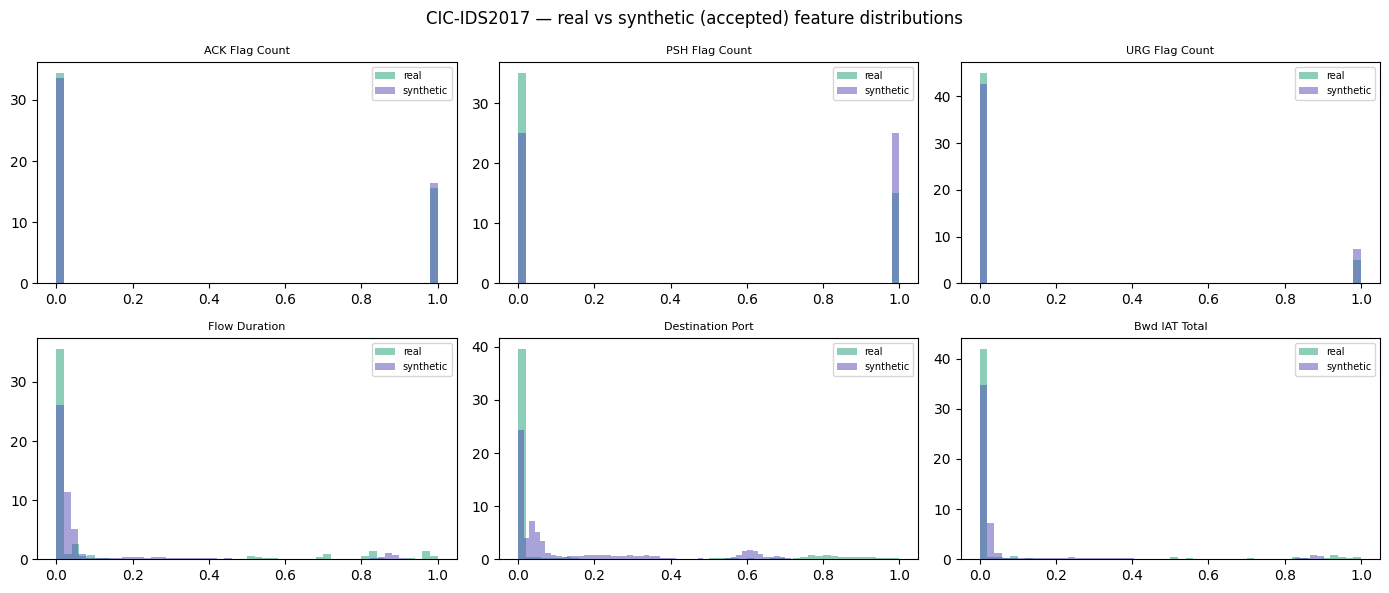

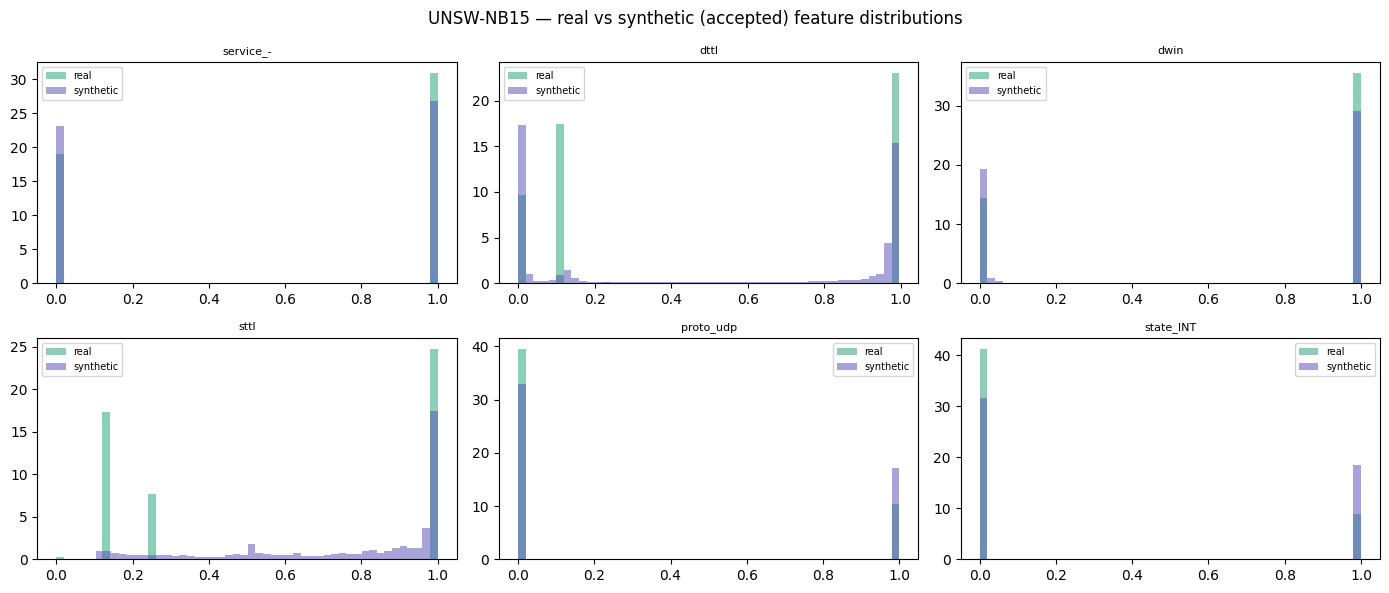

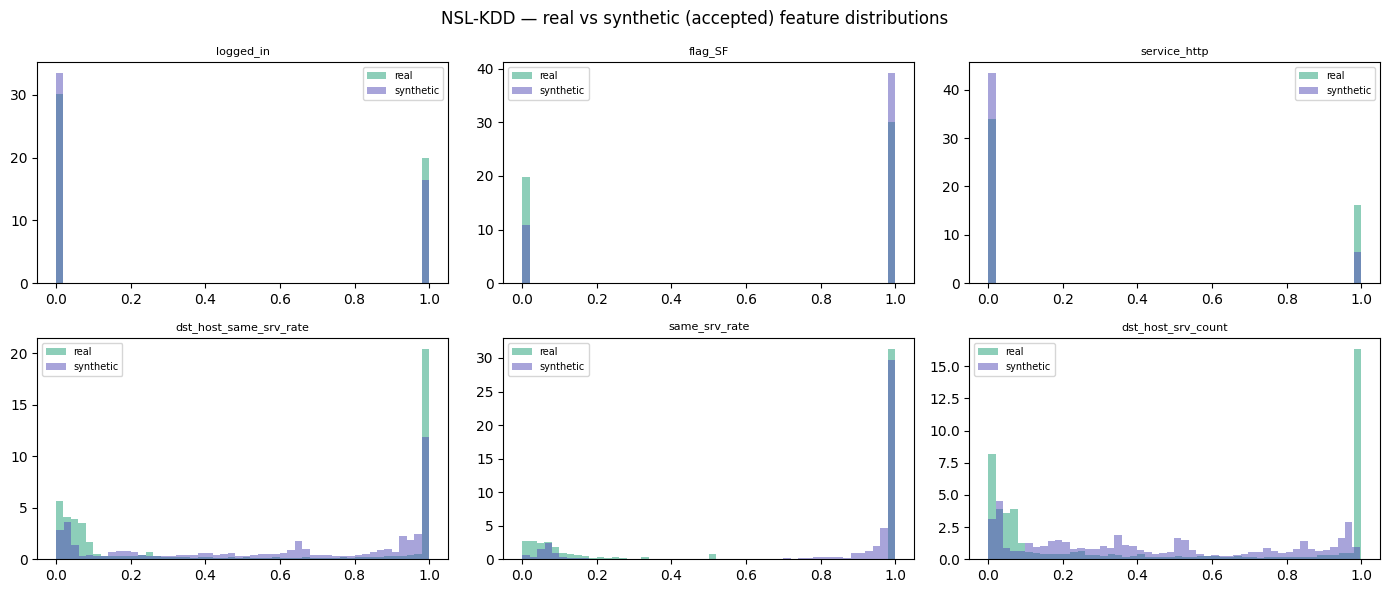

In [14]:
# ────────────────────────────────────────────────────────────────────────────
# REAL VS SYNTHETIC DISTRIBUTIONS
# Histograms of the six features with the largest real-data variance, on up
# to 20,000 records of each (plotting every record is slow and adds nothing).
# ────────────────────────────────────────────────────────────────────────────
for name in DATASETS:
    fc, X = splits[name]["feat_cols"], splits[name]["X"]
    top6 = np.argsort(X.var(axis=0))[::-1][:6]
    rng = np.random.default_rng(RANDOM_SEED)
    Xr = X[rng.choice(len(X), size=min(20_000, len(X)), replace=False)]
    Xs = synthetic[name][fc].to_numpy()[:20_000]
    fig, axes = plt.subplots(2, 3, figsize=(14, 6))
    for ax, j in zip(axes.flat, top6):
        ax.hist(Xr[:, j], bins=50, alpha=0.5, density=True, color="#1D9E75", label="real")
        ax.hist(Xs[:, j], bins=50, alpha=0.5, density=True, color="#534AB7", label="synthetic")
        ax.set_title(fc[j][:32], fontsize=8); ax.legend(fontsize=7)
    fig.suptitle(f"{name} — real vs synthetic (accepted) feature distributions")
    plt.tight_layout(); plt.savefig(OUT / f"{name}_synth_distributions.png", dpi=120); plt.show()

In [15]:
# ────────────────────────────────────────────────────────────────────────────
# SUMMARY BY STRATEGY AND SOURCE CLASS
# ────────────────────────────────────────────────────────────────────────────
for name in DATASETS:
    df = synthetic[name]
    print(f"\n{name}: {len(df):,} accepted synthetic records")
    display(pd.crosstab(df["source_class"], df["strategy"], margins=True))
print("\n✓ Synthetic data ready — continue with Step 5")


CIC-IDS2017: 490,456 accepted synthetic records


strategy,interpolation,noise,tail,All
source_class,,,,
BENIGN,9311,103393,29764,142468
Bot,10273,107,29749,40129
DDoS,20264,6983,31118,58365
DoS GoldenEye,0,4,245,249
DoS Hulk,2678,1561,4848,9087
DoS Slowhttptest,3487,77,3197,6761
DoS slowloris,1223,21,1175,2419
FTP-Patator,4124,115,5063,9302
Heartbleed,0,0,11707,11707



UNSW-NB15: 31,362 accepted synthetic records


strategy,interpolation,noise,tail,All
source_class,,,,
Analysis,1076,84,1461,2621
Backdoor,789,69,2367,3225
DoS,1699,141,2003,3843
Exploits,1618,1050,1699,4367
Fuzzers,1085,861,1331,3277
Generic,425,360,1714,2499
Normal,777,3221,2054,6052
Reconnaissance,1365,256,879,2500
Worms,801,8,2169,2978



NSL-KDD: 28,740 accepted synthetic records


strategy,interpolation,noise,tail,All
source_class,,,,
apache2,74,51,162,287
back,595,103,850,1548
ftp_write,96,0,118,214
httptunnel,0,5,236,241
imap,0,0,11,11
ipsweep,893,348,542,1783
land,29,0,119,148
mailbomb,689,14,852,1555
mscan,3,6,15,24



✓ Synthetic data ready — continue with Step 5
